# Across-State-Visits Testing with GLHMM toolbox

This test is useful for examining whether brain states, decoded from neural data, are associated with changes in a continuous variable recorded alongside the brain activity.

To focus on the statistical testing, we use synthetic data:

For this tutorial:

1. the Viterbi path — the sequence of brain states decoded by an HMM at each time point.
2. a continuous signal recorded alongside the brain data (e.g., pupil size, heart rate).



In [2]:
import numpy as np
from pathlib import Path
from glhmm import glhmm, preproc, io, graphics, statistics

# Data
vpath = np.load("./data_statistical_testing/vpath.npy")
sig_data = np.load("./data_statistical_testing/sig_data.npy")
# Check that dimensions are correct
print(f"Data dimension of vpath: {vpath.shape}")
print(f"Data dimension of sig_data: {sig_data.shape}")

Data dimension of vpath: (5000, 5)
Data dimension of sig_data: (5000, 1)


Now, let’s visualise the distinct states in the Viterbi path from our trained Hidden Markov Model.

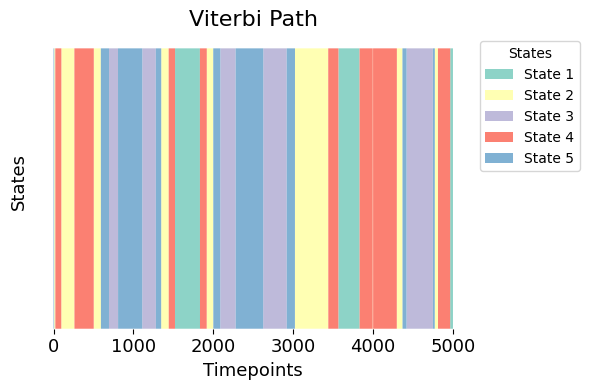

In [3]:
graphics.plot_vpath(vpath, figsize=(6,4), ylabel="States")

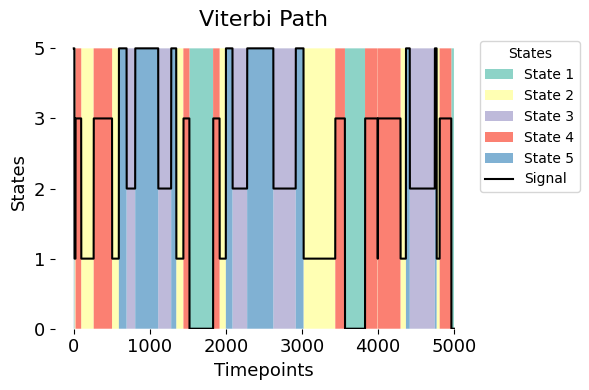

In [ ]:
# Create a 1D array from the one-hot encoded Viterbi path data
vpath_1D=statistics.generate_vpath_1D(vpath)

# Plot discrete states with the Viterbi path
graphics.plot_vpath(vpath,vpath_1D, figsize=(6,4), ylabel="States", yticks=True)

**Plot Viterbi path and signal**
This plot shows the Viterbi path (D) together with the signal (R). Each time point is color-coded based on the brain state assigned by the HMM, making it easy to compare the signal and the state changes.


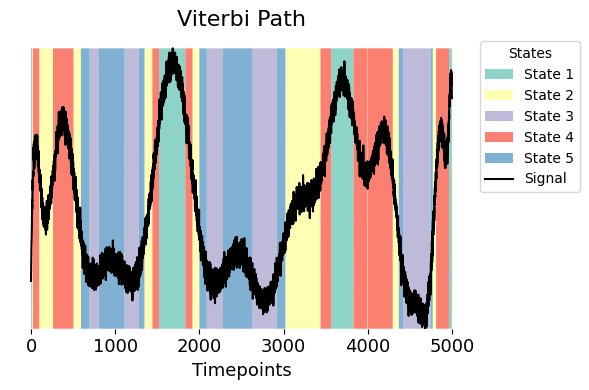

In [5]:
# Plot vpath and sig_data
graphics.plot_vpath(vpath,sig_data, figsize=(6,4))

One way to explore what each state represents is to look at how the continuous signal behaves when the system is in that state. Using the Viterbi path, we assign each time point in the signal to a state.

We can then calculate the average signal value for each state by taking the mean of the signal across all time points assigned to that state. This helps us understand the typical signal level associated with each state and gives an initial sense of how the states differ from one another.

In [6]:
vpath_1D=statistics.generate_vpath_1D(vpath)
val_state =[np.mean(sig_data[vpath_1D == i+1]) for i in range(vpath.shape[1]) ]
val_state

[4.912042797300882,
 -0.05858422375450776,
 -3.795696791047377,
 2.352225972831181,
 -2.5030418147224505]

The above figure shows a relation between the simulated measurements (sig_data) and the Viterbi path (vpath). Notably, a closer examination of the variable val_state shows distinct values assigned to each specific state:

State 1 (green) aligns with highest value

State 2 (yellow) corresponds to values in the middle, close to 0.

State 3 (purple) corresponds to the lowest negative values.

States 4 (red) and State 5 (blue) are values that fall between the extremes values. This gives us a perspective on the behavioral dynamics across different states on our signal.

# Across-Visits testing - Monte Carlo resampling

As we move on to the next part of this tutorial, let’s dive into how we can use the test_across_state_visits function. This function helps us to find connections between HMM state time course (D) and behavioral variables or individual traits (R) using Monte Carlo resampling.


**Across visits - Multivariate**

This multivariate analysis tests whether the sequence of states identified by the Viterbi path (D_data), which was inferred from the brain data using an HMM, can explain variability in a separate signal (R_data) recorded simultaneously (e.g., pupil size or behavioral responses). Importantly, the HMM is not fitted to this signal — it is trained only on the brain data — so the analysis avoids circularity.

To test the relationship, we compare the signal values across states and assess whether the observed differences are greater than what would be expected by chance. Statistical significance is determined using Monte Carlo resampling, where we randomly shuffle the state assignments.

**A significant result suggests that the brain state dynamics are meaningfully linked to the external signal.**

In [7]:
# Set the parameters for across_visits testing
method = "multivariate"
Nnull_samples = 10_000 # Number of resamples (default = 1000)
result_multivariate  =statistics.test_across_state_visits(vpath,
                                                          sig_data,
                                                          method=method,
                                                          Nnull_samples=Nnull_samples)

100%|██████████| 10000/10000 [00:24<00:00, 415.55it/s]


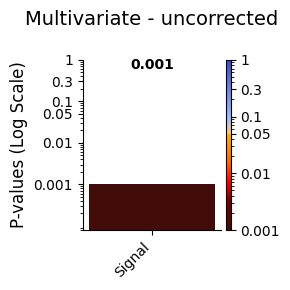

In [8]:
# Plot p-values
graphics.plot_p_values_bar(result_multivariate["pval"],
                           title_text ="Multivariate - uncorrected",
                           figsize=(3, 3),
                           alpha=0.05,
                           xticklabels=["Signal"])

**Conclusion - Multivariate**
The multivariate test between the Viterbi path and the signal resulted in a statistically significant p-value. This indicates a meaningful relationship between the brain states identified by the HMM and the signal, suggesting that the states capture important dynamics related to the observed data.

# Across visits - Univariate

The univariate analysis evaluates pairwise relationships between discrete states in the Viterbi path (D_data) and the variability in the signal (R_data). Each state is tested individually against the signal, resulting in one p-value per state. For example, with 5 states and 1 signal, the test will produce 5 p-values.

**The goal is to assess whether specific states in the Viterbi path significantly contribute to changes in the signal values over time.**

In [9]:
# Set the parameters for across_visits testing
method = "univariate"
Nnull_samples = 10_000
result_univariate  =statistics.test_across_state_visits(vpath,
                                                        sig_data,
                                                        method=method,
                                                        Nnull_samples=Nnull_samples)

100%|██████████| 10000/10000 [00:18<00:00, 528.52it/s]


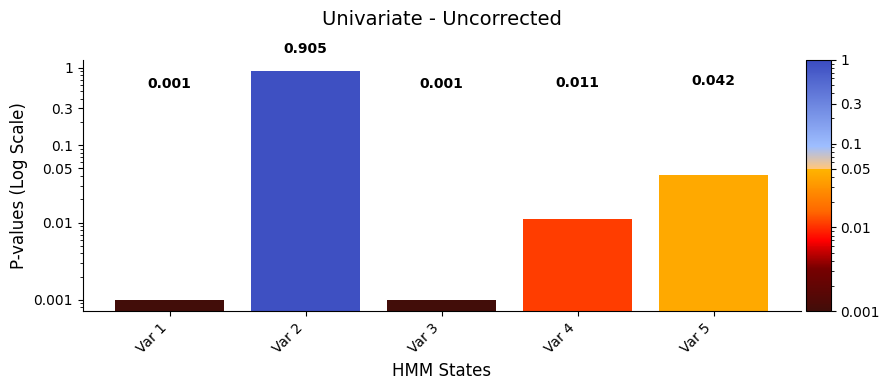

In [10]:
# Plot p-values
graphics.plot_p_values_bar(result_univariate["pval"],
                           title_text ="Univariate - Uncorrected",
                           xlabel="HMM States",
                            )

**Plot Monte Carlo resampling distribution**

Presented here are the test statistics(result["null_stat_distribution"]) of our Monte Carlo resampling distributions for different states.
The red line shows the observed statistic, while the datapoints of the histogram represent the Monte Carlo resampling distribution

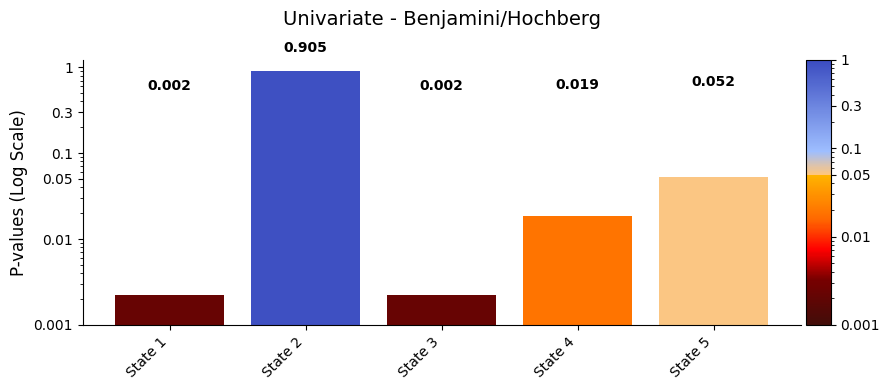

In [12]:
pval_corrected, rejected_corrected =statistics.pval_correction(result_univariate,
                                                               method='fdr_bh')
# Set the threshold of alpha to be 0.05
alpha = 0.05
variables = [f"State {i+1}" for i in range(len(pval_corrected))] # construct the variable names
graphics.plot_p_values_bar(pval_corrected,
                           alpha = alpha,
                           xticklabels=variables,
                           title_text="Univariate - Benjamini/Hochberg")

C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


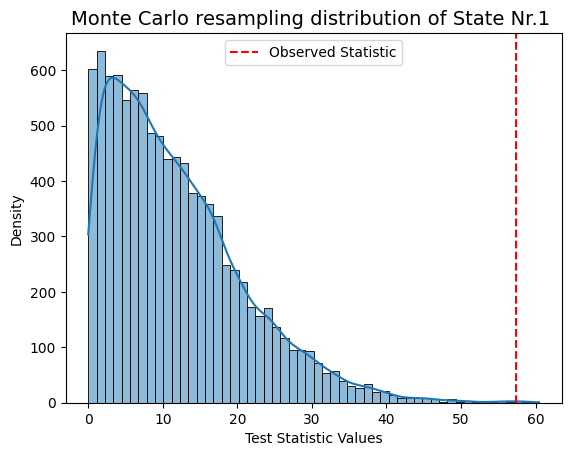

C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


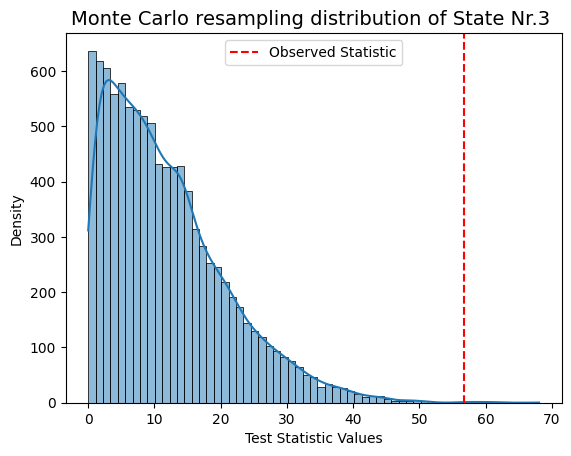

C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\_oldcore.py:1075: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)


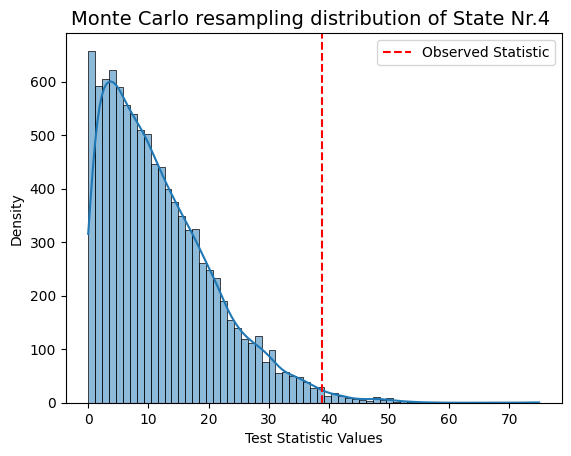

In [13]:
# Plot test statistics for pvals
significant_timestamp_position = np.where(pval_corrected < alpha)
for i in significant_timestamp_position[0]:
    graphics.plot_permutation_distribution(result_univariate["null_stat_distribution"][:,i],
                                           title_text=f"Monte Carlo resampling distribution of State Nr.{i+1} ")

**Conclusion - Univariate**

The results show that states 1, 3, and 4 have a significant relationship with the signal, while states 2 and 5 do not. The signal’s highest peak aligns with state 1, the lowest with state 3, and the second-highest with state 4, supporting these findings.

This suggests that states with extreme signal values have a stronger influence on the signal’s changes, while states 2 and 5 may have a weaker or less clear impact.



# Across visits - One-state-vs-the-rest (OSR)

The OSR test assesses whether a specific state in the Viterbi path (D_data) significantly differs from the combined influence of all other states on the signal (R_data). This test generates five p-values, one for each state.

In [14]:
# Set the parameters for across_visits testing
method = "osr"
Nnull_samples = 10_000

result_one_vs_rest  =statistics.test_across_state_visits(vpath,
                                                         sig_data,
                                                         method=method,
                                                         Nnull_samples=Nnull_samples)

100%|██████████| 10000/10000 [00:14<00:00, 674.62it/s]


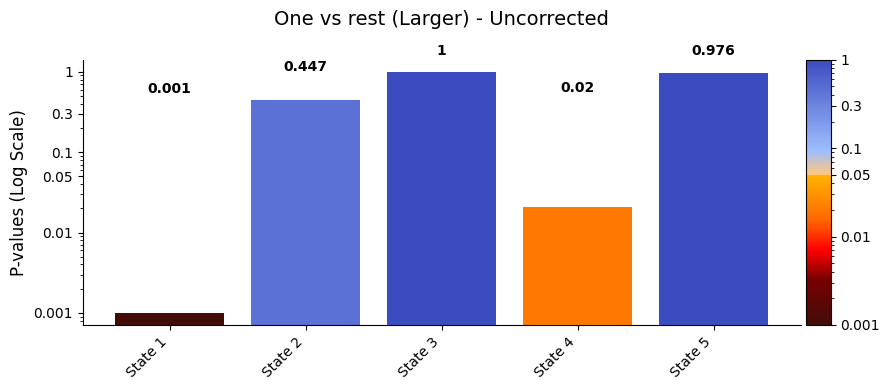

In [15]:
# Set the threshold of alpha to be 0.05
alpha = 0.05
variables = [f"State {i+1}" for i in range(len(result_one_vs_rest["pval"]))] # construct the variable names
title_text = "One vs rest (Larger) - Uncorrected"
graphics.plot_p_values_bar(result_one_vs_rest["pval"],
                           alpha = alpha,
                           xticklabels=variables,
                           title_text=title_text)

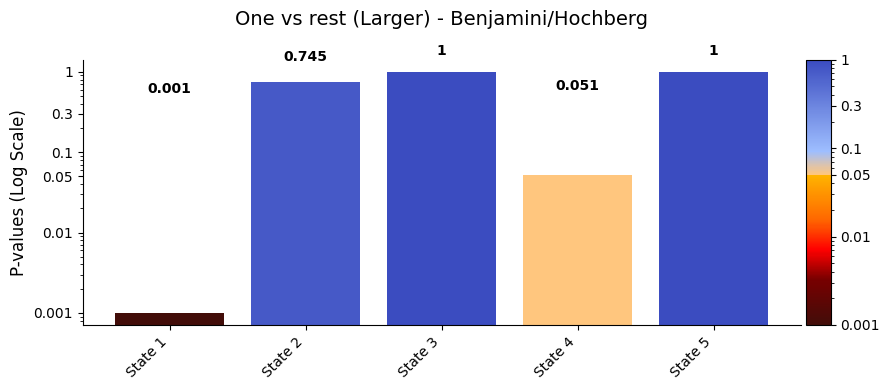

In [16]:
pval_corrected, _ =statistics.pval_correction(result_one_vs_rest,
                                              method='fdr_bh')
# Plot p-values
graphics.plot_p_values_bar(pval_corrected,alpha = alpha,
                           xticklabels=variables,
                           title_text="One vs rest (Larger) - Benjamini/Hochberg")

In [17]:
val_state

[4.912042797300882,
 -0.05858422375450776,
 -3.795696791047377,
 2.352225972831181,
 -2.5030418147224505]

**Conclusion one vs rest**

After applying the Benjamini/Hochberg method to control the False Discovery Rate (FDR), the adjusted p-values for the one vs. rest test are:

State 1: 0.005

State 2: 0.724

State 3: 1

State 4: 0.048

State 5: 1

States 1 and 4, which have the lowest adjusted p-values, also show the highest average signal values in sig_data. In the ORS, we check whether the mean signal for a given state is significantly different from the combined signal of all other states. A state doesn’t need to have the highest or lowest mean to be significant — what matters is whether its signal is consistently different from the rest, more than you’d expect by chance. That said, states with more extreme values often stand out more clearly from the shuffled data, so they’re more likely to reach significance.

# Across visits - One-state-vs-another-state (OSA)

The OSA test compares the mean signal differences between pairs of states (e.g., state 1 vs. state 2, state 1 vs. state 3, etc.). This test evaluates whether the observed mean difference between specific state pairs is statistically significant.

In [18]:
# Set the parameters for across_visits testing
method = "osa"
Nnull_samples = 10_000
test_statistics_option=True

result_state_pairs  =statistics.test_across_state_visits(vpath,
                                                         sig_data,
                                                         method=method,
                                                         Nnull_samples=Nnull_samples,)

Pairwise comparisons: 100%|██████████| 10/10 [01:19<00:00,  7.90s/it]


C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\matrix.py:260: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  annotation = ("{:" + self.fmt + "}").format(val)


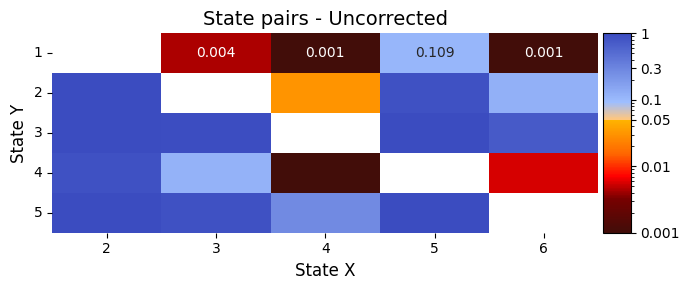

In [20]:
# Plot p-values# Plot p-values
graphics.plot_p_value_matrix(result_state_pairs["pval"],
                             title_text ="State pairs - Uncorrected",
                             figsize=(7, 3),
                             xlabel="State X",
                             ylabel="State Y",
                             alpha=0.05,
                             none_diagonal=True,
                             annot=True,
                             x_tick_min=1)


Interpreting the p-value matrix
The p-value matrix has a shape of (number of states × number of states). Each entry shows the statistical comparison between two brain states.
- Values below the diagonal (lower-left) correspond to tests where the row state is compared as less than the column state (State X < State Y).
- Values above the diagonal (upper-right) correspond to tests where the row state is compared as greater than the column state (State X > State Y).

C:\Users\pipo_\AppData\Roaming\Python\Python310\site-packages\seaborn\matrix.py:260: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  annotation = ("{:" + self.fmt + "}").format(val)


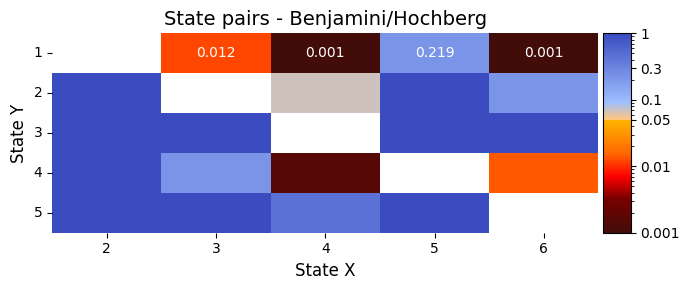

In [21]:
pval_corrected, rejected_corrected =statistics.pval_correction(result_state_pairs, method='fdr_bh')
# Plot p-values# Plot p-values
graphics.plot_p_value_matrix(pval_corrected,
                             title_text ="State pairs - Benjamini/Hochberg" ,
                             figsize=(7, 3),
                             xlabel="State X",
                             ylabel="State Y",
                             alpha=0.05,
                             none_diagonal=True,
                             annot=True,
                             x_tick_min=1)


In [22]:
# Look at the val_sates values
val_state

[4.912042797300882,
 -0.05858422375450776,
 -3.795696791047377,
 2.352225972831181,
 -2.5030418147224505]

**Conclusion - state pairs**

The results show clear differences in the signal between certain pairs of brain states:

- State 1 (the highest signal value) is significantly different from states 2, 3, and 5.

- State 3 (the lowest signal value) is significantly different from states 1 and 4.

- States 4 and 5, which are in the middle, also show a clear difference from each other and from state 1.